In [1]:
import torch
import sys

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [2]:
%cd /content

!git clone https://github.com/Basmala-ElKady/ModernTCN.git

%cd /content/ModernTCN

!git status
!git rev-parse HEAD


/content
Cloning into 'ModernTCN'...
remote: Enumerating objects: 102, done.
remote: Counting objects: 100% (102/102), done.
remote: Compressing objects: 100% (83/83), done.
remote: Total 102 (delta 31), reused 74 (delta 15), pack-reused 0 (from 0)
Receiving objects: 100% (102/102), 155.23 KiB | 1.30 MiB/s, done.
Resolving deltas: 100% (31/31), done.
/content/ModernTCN
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
95b2452930fb6899c30da9331c80c76f946a1467


In [3]:
%cd /content/ModernTCN/

!pip install -r requirements.txt


/content/ModernTCN


In [4]:
%cd /content/ModernTCN

!ls -la
!find src/training src/models src/data tests configs notebooks -maxdepth 2 -type f


/content/ModernTCN
total 52
drwxr-xr-x 10 root root 4096 Oct 26 17:50 .
drwxr-xr-x  1 root root 4096 Oct 26 17:50 ..
drwxr-xr-x  2 root root 4096 Oct 26 17:50 checkpoints
drwxr-xr-x  3 root root 4096 Oct 26 17:50 colab_sample_outputs
drwxr-xr-x  2 root root 4096 Oct 26 17:50 configs
drwxr-xr-x  8 root root 4096 Oct 26 17:50 .git
-rw-r--r--  1 root root  150 Oct 26 17:50 .gitignore
-rw-r--r--  1 root root 1513 Oct 26 17:50 README.md
-rw-r--r--  1 root root   60 Oct 26 17:50 requirements.txt
drwxr-xr-x  2 root root 4096 Oct 26 17:50 research
drwxr-xr-x  5 root root 4096 Oct 26 17:50 results
drwxr-xr-x  7 root root 4096 Oct 26 17:50 src
drwxr-xr-x  2 root root 4096 Oct 26 17:50 tests
src/training/metrics.py
src/training/evaluate.py
src/training/train.py
src/models/moderntcn.py
src/models/__init__.py
src/models/revin.py
src/models/tcn.py
src/models/dlinear.py
src/models/factory.py
src/data/preprocessing.py
src/data/__init__.py
src/data/dataset.py
tests/conftest.py
tests/test_dlinear.py
tes

In [5]:
%cd /content/ModernTCN

!python -m pytest tests -q


/content/ModernTCN
...........ss........................................................... [ 85%]
............                                                             [100%]
82 passed, 2 skipped in 14.13s


In [6]:
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [7]:
from pathlib import Path

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/ModernTCN"
)

for name in ["checkpoints", "logs", "metrics", "figures"]:
    (OUTPUT_DIR / name).mkdir(parents=True, exist_ok=True)

print("Saving results to:", OUTPUT_DIR)


Saving results to: /content/drive/MyDrive/ModernTCN


In [8]:
from pathlib import Path
import subprocess
import json
import os

REPO = Path("/content/ModernTCN")
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/ModernTCN"
)

assert REPO.exists(), (
    "Repository not found. Run the Git clone cell first."
)

for name in ["checkpoints", "logs", "metrics", "figures"]:
    (OUTPUT_DIR / name).mkdir(parents=True, exist_ok=True)

print("Repository:", REPO)
print("Drive output:", OUTPUT_DIR)
print("Repository exists:", REPO.exists())
print("Drive output exists:", OUTPUT_DIR.exists())


Repository: /content/ModernTCN
Drive output: /content/drive/MyDrive/ModernTCN
Repository exists: True
Drive output exists: True


In [9]:
%cd /content/ModernTCN

!git status
!git branch --show-current
!git log -1 --oneline
!git remote -v


/content/ModernTCN
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
main
95b2452 (HEAD -> main, origin/main, origin/HEAD) Merge pull request #21 from Basmala-ElKady/feature/revin-ablation
origin	https://github.com/Basmala-ElKady/ModernTCN.git (fetch)
origin	https://github.com/Basmala-ElKady/ModernTCN.git (push)


In [10]:
from pathlib import Path

repo = Path("/content/ModernTCN")

for name in ["README.md", "requirements.txt", "configs/default.yaml"]:
    p = repo / name
    print(f"\n{'=' * 20} {name} {'=' * 20}")
    if p.exists():
        print(p.read_text(encoding="utf-8")[:12000])
    else:
        print("FILE NOT FOUND")

for folder in ["src/training", "src/data", "src/models",
               "notebooks", "tests", "results", "data"]:
    p = repo / folder
    print(f"\n{'=' * 15} {folder} {'=' * 15}")
    if p.exists():
        for item in sorted(p.rglob("*")):
            if item.is_file():
                print(item.relative_to(repo))
    else:
        print("Folder not found")



==================== README.md ====================
﻿# ModernTCN Assignment

Deep Learning AIE332 - Assignment 1

Topic: Large kernels instead of dilation, based on ModernTCN (ICLR 2024).

## Research goals

- Compare the Lab 4 TCN baseline, DLinear, and a ModernTCN-style model.
- Evaluate ETTh1 and ETTm1.
- Use an input window of 336 and forecast horizons of 96 and 336.
- Report normalized MSE and MAE.
- Measure effective receptive fields using autograd.
- Compare at least three depthwise kernel sizes.
- Report mean and standard deviation over three seeds.
- Identify and explain a reproducible failure case.

## Rules

- Implement core model components in PyTorch.
- Do not copy the authors' model implementation.
- Select models using validation data.
- Evaluate the test set after model selection.
- Record author-code files inspected.
- Declare AI assistance in the report.

## Structure

- src/: data, models, training, and analysis.
- tests/: automated tests.
- configs/: experiment set

In [12]:
from pathlib import Path

repo = Path("/content/ModernTCN")

for name in ["ETTh1.csv", "ETTm1.csv"]:
    matches = list(repo.rglob(name))
    print(f"\n{name}:")
    if matches:
        for path in matches:
            print("Found:", path)
    else:
        print("Not found inside repository")



ETTh1.csv:
Found: /content/ModernTCN/Datasets/ETTh1.csv

ETTm1.csv:
Found: /content/ModernTCN/Datasets/ETTm1.csv


In [14]:
from pathlib import Path
import subprocess

for folder in [
    Path("/content/ModernTCN"),
    Path("/content/ModernTCN"),
]:
    print(f"\n{'=' * 20}\nFolder: {folder}")
    print("Exists:", folder.exists())

    if folder.exists():
        print("Dataset folder exists:", (folder / "Datasets").is_dir())
        print("ETTh1 exists:", (folder / "Datasets" / "ETTh1.csv").is_file())
        print("ETTm1 exists:", (folder / "Datasets" / "ETTm1.csv").is_file())

        if (folder / ".git").exists():
            result = subprocess.run(
                ["git", "-C", str(folder), "remote", "-v"],
                capture_output=True,
                text=True
            )
            print("Git remotes:")
            print(result.stdout or result.stderr)


Folder: /content/ModernTCN
Exists: True
Dataset folder exists: True
ETTh1 exists: True
ETTm1 exists: True
Git remotes:
origin	https://github.com/Basmala-ElKady/ModernTCN.git (fetch)
origin	https://github.com/Basmala-ElKady/ModernTCN.git (push)


Folder: /content/ModernTCN
Exists: True
Dataset folder exists: True
ETTh1 exists: True
ETTm1 exists: True
Git remotes:
origin	https://github.com/Basmala-ElKady/ModernTCN.git (fetch)
origin	https://github.com/Basmala-ElKady/ModernTCN.git (push)



In [15]:
from pathlib import Path

repo = Path("/content/ModernTCN")

for name in [
    "src/data/dataset.py",
    "src/data/preprocessing.py",
    "configs/default.yaml",
]:
    path = repo / name

    print(f"\n{'=' * 15} {name} {'=' * 15}")

    if path.exists():
        print(path.read_text(encoding="utf-8")[:12000])
    else:
        print("FILE NOT FOUND:", path)


=============== src/data/dataset.py ===============
"""Sliding-window datasets and dataloaders for ETTh1 / ETTm1.

Each item: x [seq_len, C], y [pred_len, C]  (normalised, float32).
Batches are therefore x [B, L, C] and y [B, H, C], matching the shared model API.
"""
from __future__ import annotations

import os

import numpy as np
import torch
from torch.utils.data import DataLoader, Dataset

from .preprocessing import StandardScaler, load_ett, split_and_normalize


class WindowDataset(Dataset):
    def __init__(self, data: np.ndarray, seq_len: int, pred_len: int):
        self.data = torch.from_numpy(np.ascontiguousarray(data))
        self.seq_len, self.pred_len = seq_len, pred_len
        self.n = len(data) - seq_len - pred_len + 1
        if self.n <= 0:
            raise ValueError("Split too short for the requested seq_len + pred_len")

    def __len__(self) -> int:
        return self.n

    def __getitem__(self, i: int):
        s = i + self.seq_len
        return self.data[i

In [16]:

from pathlib import Path

REPO = Path("/content/ModernTCN")

files_to_inspect = [
    "README.md",
    "src/models/__init__.py",
    "src/models/factory.py",
    "src/training/train.py",
    "src/training/evaluate.py",
    "src/training/metrics.py",
    "src/utils/seed.py",
    "src/utils/checkpoint.py",
    "src/analysis/ablation.py",
]

for rel in files_to_inspect:
    path = REPO / rel
    print(f"\n{'=' * 25}\nFILE: {rel}\n{'=' * 25}")

    if path.is_file():
        content = path.read_text(encoding="utf-8-sig", errors="replace")
        print(content[:10000])
    else:
        print("Not found")

# Find likely experiment entry points and existing run scripts
print("\n" + "=" * 25)
print("POSSIBLE RUNNERS")
print("=" * 25)

for pattern in [
    "main.py",
    "run*.py",
    "experiment*.py",
    "train*.py",
    "*.ipynb",
    "*.sh",
]:
    for path in REPO.rglob(pattern):
        if any(part in {".git", "__pycache__", ".venv"} for part in path.parts):
            continue
        print(path.relative_to(REPO))



FILE: README.md
# ModernTCN Assignment

Deep Learning AIE332 - Assignment 1

Topic: Large kernels instead of dilation, based on ModernTCN (ICLR 2024).

## Research goals

- Compare the Lab 4 TCN baseline, DLinear, and a ModernTCN-style model.
- Evaluate ETTh1 and ETTm1.
- Use an input window of 336 and forecast horizons of 96 and 336.
- Report normalized MSE and MAE.
- Measure effective receptive fields using autograd.
- Compare at least three depthwise kernel sizes.
- Report mean and standard deviation over three seeds.
- Identify and explain a reproducible failure case.

## Rules

- Implement core model components in PyTorch.
- Do not copy the authors' model implementation.
- Select models using validation data.
- Evaluate the test set after model selection.
- Record author-code files inspected.
- Declare AI assistance in the report.

## Structure

- src/: data, models, training, and analysis.
- tests/: automated tests.
- configs/: experiment settings.
- notebooks/: final Colab note

In [17]:
from pathlib import Path

REPO = Path("/content/ModernTCN")

files = [
    "src/models/tcn.py",
    "src/models/moderntcn.py",
    "src/models/dlinear.py",
    "tests/test_tcn.py",
    "tests/test_moderntcn.py",
    "tests/test_dlinear.py",
    "tests/test_data.py",
    "requirements.txt",
]

for rel in files:
    path = REPO / rel
    print(f"\n{'=' * 20}\n{rel}\n{'=' * 20}")

    if path.is_file():
        content = path.read_text(
            encoding="utf-8-sig",
            errors="replace"
        )
        print(content[:9000])
    else:
        print("NOT FOUND")

print("\n--- Root directory ---")
for p in sorted(REPO.iterdir()):
    print(("[DIR] " if p.is_dir() else "[FILE] ") + p.name)



src/models/tcn.py
"""TCN baseline (Bai, Kolter, Koltun 2018): stacked residual blocks of causal,
dilated 1D convolutions. Written from scratch.

External interface (shared by all models):
    x [B, L, C]  ->  predictions [B, H, C]
Forecast head: features at the LAST time step (whose causal receptive field
covers the whole window) -> Linear -> H*C values.
"""
from __future__ import annotations

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.parametrizations import weight_norm

from .revin import RevIN


class CausalConv1d(nn.Module):
    """Conv1d with left-only padding: output[t] depends on input[<= t]."""

    def __init__(self, c_in: int, c_out: int, kernel_size: int, dilation: int):
        super().__init__()
        self.left_pad = (kernel_size - 1) * dilation
        self.conv = weight_norm(nn.Conv1d(c_in, c_out, kernel_size, dilation=dilation))

    def forward(self, x: torch.Tensor) -> torch.Tensor:  # [B, C, T]
        return self.conv(F

In [18]:
from pathlib import Path

REPO = Path("/content/ModernTCN")

print("=== CONFIG FILES ===")
config_dir = REPO / "configs"
for path in sorted(config_dir.rglob("*")):
    if path.is_file() and path.suffix.lower() in {".yaml", ".yml", ".json"}:
        print(f"\n{'=' * 20} {path.relative_to(REPO)} {'=' * 20}")
        print(path.read_text(encoding="utf-8", errors="replace")[:15000])

print("\n=== ANALYSIS / EXPERIMENT FILES ===")
for folder_name in ("src/analysis", "src/utils", "results", "checkpoints"):
    folder = REPO / folder_name
    print(f"\n--- {folder_name} ---")
    if folder.exists():
        for path in sorted(folder.rglob("*")):
            if path.is_file() and (
                path.suffix in {".py", ".json", ".csv", ".md"}
                or path.name.endswith(".yaml")
            ):
                print(path.relative_to(REPO))
    else:
        print("NOT FOUND")


=== CONFIG FILES ===

==================== configs/default.yaml ====================
﻿data:
  datasets:
    - ETTh1
    - ETTm1
  input_length: 336
  forecast_horizons:
    - 96
    - 336
  features: M
  normalization: standard

training:
  batch_size: 32
  learning_rate: 0.001
  epochs: 10
  patience: 3
  seeds:
    - 42
    - 123
    - 2026

evaluation:
  metrics:
    - MSE
    - MAE
  metric_space: normalized

experiment:
  models:
    - tcn
    - moderntcn
    - dlinear
  device: auto

=== ANALYSIS / EXPERIMENT FILES ===

--- src/analysis ---
src/analysis/ablation.py
src/analysis/failure_analysis.py
src/analysis/receptive_field.py
src/analysis/revin_ablation.py

--- src/utils ---
src/utils/checkpoint.py
src/utils/seed.py

--- results ---

--- checkpoints ---


In [19]:

from pathlib import Path
import json

REPO = Path("/content/ModernTCN")

# 1. Inspect existing analysis utilities
analysis_files = [
    "src/analysis/ablation.py",
    "src/analysis/receptive_field.py",
    "src/analysis/failure_analysis.py",
    "src/analysis/revin_ablation.py",
    "src/utils/checkpoint.py",
    "src/utils/seed.py",
]

for rel in analysis_files:
    path = REPO / rel
    print(f"\n{'=' * 25}\n{rel}\n{'=' * 25}")
    if path.is_file():
        print(path.read_text(encoding="utf-8-sig", errors="replace")[:12000])
    else:
        print("NOT FOUND")

# 2. Inspect notebook cell headings and code structure
nb_path = REPO / "src/analysis/notebook.ipynb"

print("\n=== NOTEBOOK OVERVIEW ===")
if nb_path.is_file():
    nb = json.loads(nb_path.read_text(encoding="utf-8"))
    for i, cell in enumerate(nb.get("cells", [])):
        source = "".join(cell.get("source", []))
        if cell.get("cell_type") == "markdown":
            print(f"\n[Markdown cell {i}]\n{source[:500]}")
        else:
            lines = source.strip().splitlines()
            preview = "\n".join(lines[:8])
            print(f"\n[Code cell {i}] ({len(lines)} lines)\n{preview[:900]}")
else:
    print("Notebook not found at src/analysis/notebook.ipynb")



src/analysis/ablation.py


src/analysis/receptive_field.py


src/analysis/failure_analysis.py


src/analysis/revin_ablation.py
"""Fair ModernTCN RevIN ablation runner and cross-seed result aggregation.

Example (requires ``data/ETTh1.csv``)::

    python -m src.analysis.revin_ablation --data-dir data

The runner trains RevIN-on and RevIN-off independently for every same seed;
it selects checkpoints only by validation MSE and evaluates those checkpoints
once on the test split.
"""
from __future__ import annotations

import argparse
import csv
import json
from collections import defaultdict
from copy import deepcopy
from pathlib import Path
from typing import Iterable, Mapping

import numpy as np
import torch
import yaml

from src.data.dataset import build_dataloaders
from src.models.moderntcn import build_moderntcn
from src.training.evaluate import evaluate_model
from src.training.train import train_model
from src.utils.checkpoint import load_checkpoint
from src.utils.seed import set_s

In [20]:

# ============================================================
# ModernTCN Project — Full Baseline Experiment Runner
# 3 models x 2 datasets x 2 horizons x 3 seeds = 36 runs
# No pilot, no reduced training subset.
# ============================================================

from pathlib import Path
from copy import deepcopy
from itertools import product
import sys
import json
import csv
import time
import traceback
import gc

import numpy as np
import pandas as pd
import torch
import yaml

# -------------------- 1. Paths and persistent storage --------------------

REPO = Path("/content/ModernTCN")
assert REPO.is_dir(), f"Repository not found: {REPO}"

if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from google.colab import drive
drive.mount("/content/drive")

DATA_DIR = REPO / "Datasets"
OUTPUT_DIR = Path("/content/drive/MyDrive/ModernTCN_full_experiments")
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

CONFIG_PATH = REPO / "configs" / "default.yaml"

with CONFIG_PATH.open("r", encoding="utf-8-sig") as f:
    PROJECT_CFG = yaml.safe_load(f)

DATA_CFG = PROJECT_CFG["data"]
TRAIN_CFG = PROJECT_CFG["training"]
EXP_CFG = PROJECT_CFG["experiment"]

DATASETS = list(DATA_CFG["datasets"])
HORIZONS = list(DATA_CFG["forecast_horizons"])
MODELS = list(EXP_CFG["models"])
SEEDS = list(TRAIN_CFG["seeds"])
INPUT_LENGTH = int(DATA_CFG["input_length"])

# Verify every required CSV before starting expensive training.
for dataset in DATASETS:
    csv_path = DATA_DIR / f"{dataset}.csv"
    if not csv_path.is_file():
        raise FileNotFoundError(f"Missing dataset: {csv_path}")

DEVICE = (
    "cuda" if torch.cuda.is_available()
    else "cpu"
) if EXP_CFG.get("device", "auto") == "auto" else EXP_CFG["device"]

print("Repository:", REPO)
print("Data directory:", DATA_DIR)
print("Output directory:", OUTPUT_DIR)
print("Device:", DEVICE)
print("Datasets:", DATASETS)
print("Models:", MODELS)
print("Horizons:", HORIZONS)
print("Seeds:", SEEDS)
print("Planned baseline runs:", len(DATASETS) * len(MODELS) * len(HORIZONS) * len(SEEDS))

if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# -------------------- 2. Existing project interfaces --------------------

from src.data.dataset import build_dataloaders
from src.models.factory import build_model
from src.training.train import train_model
from src.training.evaluate import evaluate_model
from src.utils.checkpoint import load_checkpoint
from src.utils.seed import set_seed

RAW_PATH = OUTPUT_DIR / "baseline_raw.csv"
SUMMARY_PATH = OUTPUT_DIR / "baseline_summary.csv"
MANIFEST_PATH = OUTPUT_DIR / "baseline_manifest.json"

RAW_COLUMNS = [
    "model", "dataset", "horizon", "seed", "status",
    "best_epoch", "best_val_mse", "test_mse", "test_mae",
    "training_seconds", "device", "parameters", "checkpoint", "error",
]

# Explicit architecture settings, so results don't silently depend on
# future changes to source-code defaults.
ARCH_CONFIGS = {
    "tcn": {
        "hidden_channels": 64,
        "kernel_size": 3,
        "dropout": 0.1,
        "use_revin": False,
    },
    "moderntcn": {
        "embed_dim": 64,
        "depth": 3,
        "kernel_size": 31,
        "small_kernel_size": 5,
        "patch_size": 16,
        "patch_stride": 8,
        "ffn_ratio": 2.0,
        "dropout": 0.1,
        "use_revin": True,
        "revin_affine": True,
    },
    "dlinear": {
        "moving_avg_kernel": 25,
        "individual": False,
    },
}

# Validate the requested model names against the architecture map.
unknown_models = set(MODELS) - set(ARCH_CONFIGS)
if unknown_models:
    raise ValueError(f"Missing explicit architecture config for: {unknown_models}")

def write_raw(rows):
    pd.DataFrame(rows, columns=RAW_COLUMNS).to_csv(RAW_PATH, index=False)

def write_summary(rows):
    completed = [
        r for r in rows
        if r.get("status") == "completed"
        and pd.notna(r.get("test_mse"))
        and pd.notna(r.get("test_mae"))
    ]

    if not completed:
        pd.DataFrame().to_csv(SUMMARY_PATH, index=False)
        return

    df = pd.DataFrame(completed)
    summary = (
        df.groupby(["model", "dataset", "horizon"], as_index=False)
          .agg(
              runs=("seed", "count"),
              mse_mean=("test_mse", "mean"),
              mse_sample_std=("test_mse", "std"),
              mae_mean=("test_mae", "mean"),
              mae_sample_std=("test_mae", "std"),
              best_val_mse_mean=("best_val_mse", "mean"),
              training_seconds_mean=("training_seconds", "mean"),
          )
          .sort_values(["dataset", "horizon", "model"])
    )
    # pandas std uses ddof=1, i.e. sample standard deviation.
    summary.to_csv(SUMMARY_PATH, index=False)

# Load previous run records so completed experiments can be skipped.
if RAW_PATH.exists():
    old_df = pd.read_csv(RAW_PATH)
    rows = old_df.to_dict("records")
    rows = [
        {col: row.get(col, "") for col in RAW_COLUMNS}
        for row in rows
    ]
else:
    rows = []

completed_keys = set()
for row in rows:
    if row.get("status") != "completed":
        continue
    cp = Path(str(row.get("checkpoint", "")))
    if cp.is_file():
        completed_keys.add((
            str(row["model"]), str(row["dataset"]),
            int(row["horizon"]), int(row["seed"])
        ))

manifest = {
    "config_file": str(CONFIG_PATH),
    "data_dir": str(DATA_DIR),
    "output_dir": str(OUTPUT_DIR),
    "device": DEVICE,
    "datasets": DATASETS,
    "models": MODELS,
    "input_length": INPUT_LENGTH,
    "horizons": HORIZONS,
    "seeds": SEEDS,
    "batch_size": int(TRAIN_CFG["batch_size"]),
    "learning_rate": float(TRAIN_CFG["learning_rate"]),
    "epochs": int(TRAIN_CFG["epochs"]),
    "patience": int(TRAIN_CFG["patience"]),
    "architecture_configs": ARCH_CONFIGS,
    "metric_space": PROJECT_CFG["evaluation"]["metric_space"],
    "reporting_std_ddof": 1,
}
MANIFEST_PATH.write_text(json.dumps(manifest, indent=2), encoding="utf-8")

# -------------------- 3. Run every baseline combination --------------------

experiments = list(product(MODELS, DATASETS, HORIZONS, SEEDS))
total = len(experiments)

for index, (model_name, dataset, horizon, seed) in enumerate(experiments, start=1):
    key = (model_name, dataset, int(horizon), int(seed))

    if key in completed_keys:
        print(f"\n[{index}/{total}] SKIP completed: {key}")
        continue

    run_name = f"{model_name}_{dataset}_h{horizon}_seed{seed}"
    checkpoint_path = CHECKPOINT_DIR / f"{run_name}.pt"

    print("\n" + "=" * 78)
    print(f"[{index}/{total}] START {run_name}")
    print("=" * 78)

    started = time.time()
    row = {
        "model": model_name,
        "dataset": dataset,
        "horizon": int(horizon),
        "seed": int(seed),
        "status": "running",
        "best_epoch": None,
        "best_val_mse": None,
        "test_mse": None,
        "test_mae": None,
        "training_seconds": None,
        "device": DEVICE,
        "parameters": None,
        "checkpoint": str(checkpoint_path),
        "error": "",
    }

    try:
        set_seed(int(seed))

        # Flat config required by the repository's existing training/data APIs.
        config = {
            "model_name": model_name,
            "dataset": dataset,
            "data_dir": str(DATA_DIR),
            "input_length": INPUT_LENGTH,
            "forecast_horizon": int(horizon),
            "num_variables": 7,
            "num_features": 7,
            "batch_size": int(TRAIN_CFG["batch_size"]),
            "learning_rate": float(TRAIN_CFG["learning_rate"]),
            "epochs": int(TRAIN_CFG["epochs"]),
            "patience": int(TRAIN_CFG["patience"]),
            "seed": int(seed),
            "device": DEVICE,
        }

        if model_name in ("tcn", "moderntcn"):
            config[model_name] = deepcopy(ARCH_CONFIGS[model_name])
        else:
            config.update(deepcopy(ARCH_CONFIGS["dlinear"]))

        loaders = build_dataloaders(config)
        model = build_model(config)
        row["parameters"] = sum(
            p.numel() for p in model.parameters() if p.requires_grad
        )

        if DEVICE == "cuda":
            torch.cuda.reset_peak_memory_stats()

        train_result = train_model(
            model,
            loaders["train"],
            loaders["val"],
            config,
            checkpoint_path,
        )

        # IMPORTANT: evaluate the BEST validation checkpoint, not the last epoch.
        load_checkpoint(
            checkpoint_path,
            model,
            device=DEVICE,
        )

        model.eval()
        metrics = evaluate_model(model, loaders["test"], DEVICE)

        row.update({
            "status": "completed",
            "best_epoch": int(train_result["best_epoch"]),
            "best_val_mse": float(train_result["best_val_mse"]),
            "test_mse": float(metrics["mse"]),
            "test_mae": float(metrics["mae"]),
            "training_seconds": round(time.time() - started, 2),
            "error": "",
        })

        print(
            f"COMPLETE | best epoch={row['best_epoch']} "
            f"| val MSE={row['best_val_mse']:.6f} "
            f"| test MSE={row['test_mse']:.6f} "
            f"| test MAE={row['test_mae']:.6f}"
        )

        completed_keys.add(key)

    except Exception as exc:
        row["status"] = "failed"
        row["training_seconds"] = round(time.time() - started, 2)
        row["error"] = f"{type(exc).__name__}: {exc}"
        print("RUN FAILED:", row["error"])
        traceback.print_exc()

    finally:
        rows.append(row)
        write_raw(rows)
        write_summary(rows)

        # Save the current state after every run.
        manifest["completed_runs"] = len(completed_keys)
        manifest["failed_runs"] = sum(
            1 for r in rows if r.get("status") == "failed"
        )
        MANIFEST_PATH.write_text(
            json.dumps(manifest, indent=2), encoding="utf-8"
        )

        if "model" in locals():
            del model
        if "loaders" in locals():
            del loaders
        if "config" in locals():
            del config

        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

# -------------------- 4. Final report --------------------

final_df = pd.read_csv(RAW_PATH)
completed_df = final_df[final_df["status"] == "completed"]
failed_df = final_df[final_df["status"] == "failed"]

print("\n" + "=" * 78)
print("BASELINE EXPERIMENT RUN SUMMARY")
print("=" * 78)
print(f"Planned runs: {total}")
print(f"Completed records: {len(completed_df)}")
print(f"Failed records: {len(failed_df)}")
print(f"Raw results: {RAW_PATH}")
print(f"Aggregated summary: {SUMMARY_PATH}")
print(f"Checkpoints: {CHECKPOINT_DIR}")

if not completed_df.empty:
    display(pd.read_csv(SUMMARY_PATH))

if not failed_df.empty:
    print("\nFailed runs to investigate:")
    display(failed_df[["model", "dataset", "horizon", "seed", "error"]])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Repository: /content/ModernTCN
Data directory: /content/ModernTCN/Datasets
Output directory: /content/drive/MyDrive/ModernTCN_full_experiments
Device: cuda
Datasets: ['ETTh1', 'ETTm1']
Models: ['tcn', 'moderntcn', 'dlinear']
Horizons: [96, 336]
Seeds: [42, 123, 2026]
Planned baseline runs: 36
GPU: Tesla T4

[1/36] START tcn_ETTh1_h96_seed42
Epoch 1/10 | train_mse=0.529846 | val_mse=0.945430 | val_mae=0.659455
Epoch 2/10 | train_mse=0.357187 | val_mse=0.900458 | val_mae=0.638765
Epoch 3/10 | train_mse=0.319152 | val_mse=0.893688 | val_mae=0.639432
Epoch 4/10 | train_mse=0.294053 | val_mse=0.916649 | val_mae=0.646762
Epoch 5/10 | train_mse=0.278330 | val_mse=0.927953 | val_mae=0.652726
Epoch 6/10 | train_mse=0.265269 | val_mse=0.935798 | val_mae=0.654415
Early stopping at epoch 6.
COMPLETE | best epoch=3 | val MSE=0.893688 | test MSE=0.743854 | test MAE=0.67319

,model,dataset,horizon,runs,mse_mean,mse_sample_std,mae_mean,mae_sample_std,best_val_mse_mean,training_seconds_mean
0,dlinear,ETTh1,96,3,0.385165,0.004460,0.408255,0.004823,0.649679,4.166667
1,moderntcn,ETTh1,96,3,0.379897,0.002332,0.403238,0.001432,0.688237,19.283333
2,tcn,ETTh1,96,3,0.778882,0.039454,0.687390,0.022161,0.923847,50.080000
3,dlinear,ETTh1,336,3,0.469123,0.016526,0.467969,0.014354,1.043113,5.380000
4,moderntcn,ETTh1,336,3,0.448098,0.006915,0.446636,0.004484,1.218732,13.546667
5,tcn,ETTh1,336,3,0.980616,0.039302,0.773062,0.019866,1.230478,70.973333
6,dlinear,ETTm1,96,3,0.307833,0.001286,0.353115,0.002029,0.386479,18.910000
7,moderntcn,ETTm1,96,3,0.296952,0.004445,0.349002,0.002451,0.380120,58.796667
8,tcn,ETTm1,96,3,0.537501,0.020190,0.523882,0.017661,0.626034,170.880000
9,dlinear,ETTm1,336,3,0.387177,0.006326,0.407188,0.008209,0.617456,25.490000


In [21]:

# ModernTCN kernel-size ablation
# 3 kernel sizes x 3 seeds = 9 runs
# Fixed dataset/horizon: ETTh1, 96

import sys, time, json
from pathlib import Path

import pandas as pd
import torch
import yaml

REPO = Path("/content/ModernTCN")
DATA_DIR = REPO / "Datasets"
OUT = Path("/content/drive/MyDrive/ModernTCN_full_experiments")
ABLATION_DIR = OUT / "kernel_ablation"
CKPT_DIR = ABLATION_DIR / "checkpoints"

ABLATION_DIR.mkdir(parents=True, exist_ok=True)
CKPT_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(REPO))
import os
os.chdir(REPO)

from src.data.dataset import build_dataloaders
from src.models.factory import build_model
from src.training.train import train_model
from src.training.evaluate import evaluate_model
from src.utils.seed import set_seed
from src.utils.checkpoint import load_checkpoint

with open(REPO / "configs/default.yaml", encoding="utf-8-sig") as f:
    cfg = yaml.safe_load(f)

DATASET = "ETTh1"
HORIZON = 96
SEEDS = [42, 123, 2026]
KERNEL_SIZES = [15, 31, 51]
RESULTS_FILE = ABLATION_DIR / "kernel_ablation_raw.csv"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Ablation output:", ABLATION_DIR)

base_config = {
    "data_dir": str(DATA_DIR),
    "dataset": DATASET,
    "input_length": cfg["data"]["input_length"],
    "forecast_horizon": HORIZON,
    "batch_size": cfg["training"]["batch_size"],
    "learning_rate": cfg["training"]["learning_rate"],
    "epochs": cfg["training"]["epochs"],
    "patience": cfg["training"]["patience"],
    "device": str(device),
    "num_variables": 7,
    "model_name": "moderntcn",
    "moderntcn": {
        "embed_dim": 64,
        "depth": 3,
        "kernel_size": 31,  # overridden per run
        "small_kernel_size": 5,
        "patch_size": 16,
        "patch_stride": 8,
        "ffn_ratio": 2.0,
        "dropout": 0.1,
        "use_revin": True,
        "revin_affine": True,
    },
}

if RESULTS_FILE.exists():
    results_df = pd.read_csv(RESULTS_FILE)
else:
    results_df = pd.DataFrame()

def save_results(df):
    df.to_csv(RESULTS_FILE, index=False)

completed = set()
if not results_df.empty:
    for _, row in results_df.iterrows():
        if row.get("status") == "completed":
            key = (int(row["kernel_size"]), int(row["seed"]))
            checkpoint = CKPT_DIR / (
                f"moderntcn_k{key[0]}_{DATASET}_h{HORIZON}_seed{key[1]}.pt"
            )
            if checkpoint.exists():
                completed.add(key)

total = len(KERNEL_SIZES) * len(SEEDS)
run_number = 0

for kernel_size in KERNEL_SIZES:
    for seed in SEEDS:
        run_number += 1
        key = (kernel_size, seed)

        checkpoint_path = CKPT_DIR / (
            f"moderntcn_k{kernel_size}_{DATASET}_h{HORIZON}_seed{seed}.pt"
        )

        if key in completed:
            print(f"[{run_number}/{total}] Already completed; skipping {key}")
            continue

        print("\n" + "=" * 70)
        print(
            f"[{run_number}/{total}] ModernTCN | {DATASET} | "
            f"h={HORIZON} | kernel={kernel_size} | seed={seed}"
        )

        row = {
            "model": "moderntcn",
            "dataset": DATASET,
            "horizon": HORIZON,
            "kernel_size": kernel_size,
            "seed": seed,
            "status": "failed",
        }

        started = time.time()

        try:
            set_seed(seed)

            run_config = dict(base_config)
            run_config["seed"] = seed
            run_config["moderntcn"] = dict(base_config["moderntcn"])
            run_config["moderntcn"]["kernel_size"] = kernel_size

            loaders = build_dataloaders(run_config)
            model = build_model(run_config)

            train_info = train_model(
                model,
                loaders["train"],
                loaders["val"],
                run_config,
                checkpoint_path,
            )

            # Evaluate the BEST validation checkpoint, not final epoch weights.
            load_checkpoint(
                checkpoint_path,
                model,
                device=str(device),
            )
            test_metrics = evaluate_model(
                model,
                loaders["test"],
                device,
            )

            row.update({
                "status": "completed",
                "best_epoch": train_info["best_epoch"],
                "best_val_mse": train_info["best_val_mse"],
                "test_mse": test_metrics["mse"],
                "test_mae": test_metrics["mae"],
                "training_seconds": round(time.time() - started, 2),
                "checkpoint": str(checkpoint_path),
            })

            print(
                f"COMPLETE | kernel={kernel_size} | "
                f"test MSE={row['test_mse']:.6f} | "
                f"test MAE={row['test_mae']:.6f}"
            )

        except Exception as e:
            row["error"] = repr(e)
            print("FAILED:", repr(e))

        # Persist every run immediately.
        results_df = pd.concat(
            [results_df, pd.DataFrame([row])],
            ignore_index=True,
        )
        save_results(results_df)

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

successful = results_df[results_df["status"] == "completed"].copy()

if not successful.empty:
    summary = successful.groupby(
        ["dataset", "horizon", "kernel_size"]
    ).agg(
        runs=("test_mse", "count"),
        mse_mean=("test_mse", "mean"),
        mse_std=("test_mse", "std"),
        mae_mean=("test_mae", "mean"),
        mae_std=("test_mae", "std"),
        best_val_mse_mean=("best_val_mse", "mean"),
    ).reset_index()

    summary.to_csv(
        ABLATION_DIR / "kernel_ablation_summary.csv",
        index=False,
    )

    print("\nKERNEL ABLATION SUMMARY")
    display(summary.round(6))
    print("Raw:", RESULTS_FILE)
    print("Summary:", ABLATION_DIR / "kernel_ablation_summary.csv")
else:
    print("No successful ablation runs yet. Check the error messages above.")


Device: cuda
Ablation output: /content/drive/MyDrive/ModernTCN_full_experiments/kernel_ablation

[1/9] ModernTCN | ETTh1 | h=96 | kernel=15 | seed=42
Epoch 1/10 | train_mse=0.389784 | val_mse=0.697704 | val_mae=0.565675
Epoch 2/10 | train_mse=0.347295 | val_mse=0.700081 | val_mae=0.564760
Epoch 3/10 | train_mse=0.335946 | val_mse=0.681503 | val_mae=0.555257
Epoch 4/10 | train_mse=0.325447 | val_mse=0.685011 | val_mae=0.555752
Epoch 5/10 | train_mse=0.312013 | val_mse=0.713961 | val_mae=0.565318
Epoch 6/10 | train_mse=0.293889 | val_mse=0.777891 | val_mae=0.589814
Early stopping at epoch 6.
COMPLETE | kernel=15 | test MSE=0.377882 | test MAE=0.401922

[2/9] ModernTCN | ETTh1 | h=96 | kernel=15 | seed=123
Epoch 1/10 | train_mse=0.389551 | val_mse=0.725818 | val_mae=0.577040
Epoch 2/10 | train_mse=0.346215 | val_mse=0.690412 | val_mae=0.559337
Epoch 3/10 | train_mse=0.334295 | val_mse=0.695214 | val_mae=0.565334
Epoch 4/10 | train_mse=0.323954 | val_mse=0.697834 | val_mae=0.559203
Epoch 5

,dataset,horizon,kernel_size,runs,mse_mean,mse_std,mae_mean,mae_std,best_val_mse_mean
0,ETTh1,96,15,3,0.378775,0.001288,0.402369,0.001372,0.685340
1,ETTh1,96,31,3,0.379897,0.002332,0.403238,0.001432,0.688237
2,ETTh1,96,51,3,0.383009,0.003892,0.405309,0.002737,0.691568


Raw: /content/drive/MyDrive/ModernTCN_full_experiments/kernel_ablation/kernel_ablation_raw.csv
Summary: /content/drive/MyDrive/ModernTCN_full_experiments/kernel_ablation/kernel_ablation_summary.csv


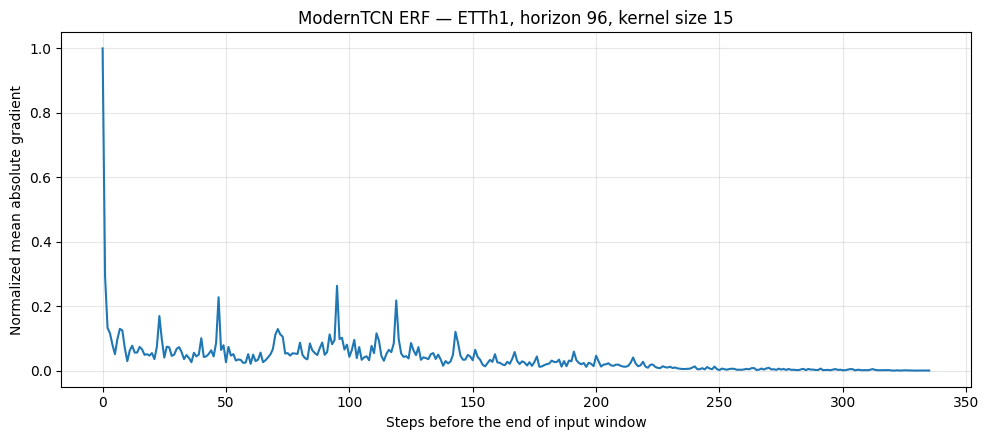

Device: cuda
Input shape: (1, 336, 7)
Prediction shape: (1, 96, 7)
Forecast positions evaluated: [0, 24, 48, 72, 95]
ERF summary: {'steps_for_50pct_gradient_mass': 85, 'steps_for_90pct_gradient_mass': 187}
CSV: /content/drive/MyDrive/ModernTCN_full_experiments/erf_analysis/moderntcn_etth1_h96_kernel15_erf.csv
Plot: /content/drive/MyDrive/ModernTCN_full_experiments/erf_analysis/moderntcn_etth1_h96_kernel15_erf.png


In [22]:

# Effective Receptive Field (ERF) via input gradients
# No training: loads the existing kernel=15 checkpoint.

import sys, os
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import yaml
import matplotlib.pyplot as plt

REPO = Path("/content/ModernTCN")
OUT = Path("/content/drive/MyDrive/ModernTCN_full_experiments")
ABLATION_DIR = OUT / "kernel_ablation"
ERF_DIR = OUT / "erf_analysis"
ERF_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(REPO))
os.chdir(REPO)

from src.data.dataset import build_dataloaders
from src.models.factory import build_model
from src.utils.checkpoint import load_checkpoint

with open(REPO / "configs/default.yaml", encoding="utf-8-sig") as f:
    cfg = yaml.safe_load(f)

checkpoint_path = (
    ABLATION_DIR / "checkpoints" /
    "moderntcn_k15_ETTh1_h96_seed42.pt"
)

assert checkpoint_path.exists(), (
    f"Checkpoint not found: {checkpoint_path}"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

run_config = {
    "data_dir": str(REPO / "Datasets"),
    "dataset": "ETTh1",
    "input_length": 336,
    "forecast_horizon": 96,
    "batch_size": 1,
    "learning_rate": cfg["training"]["learning_rate"],
    "epochs": cfg["training"]["epochs"],
    "patience": cfg["training"]["patience"],
    "device": str(device),
    "num_variables": 7,
    "model_name": "moderntcn",
    "seed": 42,
    "moderntcn": {
        "embed_dim": 64,
        "depth": 3,
        "kernel_size": 15,
        "small_kernel_size": 5,
        "patch_size": 16,
        "patch_stride": 8,
        "ffn_ratio": 2.0,
        "dropout": 0.1,
        "use_revin": True,
        "revin_affine": True,
    },
}

loaders = build_dataloaders(run_config)
model = build_model(run_config).to(device)

load_checkpoint(checkpoint_path, model, device=str(device))
model.eval()

x_batch, _ = next(iter(loaders["test"]))
x = x_batch[:1].to(device=device, dtype=torch.float32)
x.requires_grad_(True)

# One forward pass; measure absolute input gradients for several
# forecast positions and all output variables.
prediction = model(x)

input_length = x.shape[1]
forecast_horizon = prediction.shape[1]
num_variables = prediction.shape[2]

target_positions = sorted(set([
    0,
    forecast_horizon // 4,
    forecast_horizon // 2,
    (3 * forecast_horizon) // 4,
    forecast_horizon - 1,
]))

gradient_profiles = []

for horizon_idx in target_positions:
    for variable_idx in range(num_variables):
        grad = torch.autograd.grad(
            outputs=prediction[0, horizon_idx, variable_idx],
            inputs=x,
            retain_graph=True,
            create_graph=False,
        )[0]

        # Aggregate absolute gradient across input variables.
        profile = grad[0].abs().mean(dim=-1)
        gradient_profiles.append(profile.detach().cpu().numpy())

# Average over forecast positions and output variables.
erf = np.mean(np.stack(gradient_profiles), axis=0)

# Normalize for visualization; retain raw gradients too.
max_value = float(erf.max())
if max_value > 0:
    erf_normalized = erf / max_value
else:
    erf_normalized = erf

df = pd.DataFrame({
    "input_timestep": np.arange(input_length),
    "steps_before_forecast": np.arange(input_length - 1, -1, -1),
    "mean_absolute_gradient": erf,
    "normalized_gradient": erf_normalized,
})

csv_path = ERF_DIR / "moderntcn_etth1_h96_kernel15_erf.csv"
plot_path = ERF_DIR / "moderntcn_etth1_h96_kernel15_erf.png"
df.to_csv(csv_path, index=False)

plt.figure(figsize=(10, 4.5))
plt.plot(df["steps_before_forecast"], df["normalized_gradient"])
plt.xlabel("Steps before the end of input window")
plt.ylabel("Normalized mean absolute gradient")
plt.title("ModernTCN ERF — ETTh1, horizon 96, kernel size 15")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(plot_path, dpi=180, bbox_inches="tight")
plt.show()

# Quantify where 50% and 90% of the gradient mass is concentrated.
mass = erf.sum()
if mass > 0:
    # Sort by temporal distance from the end of the input window.
    ordered = erf[::-1]
    cumulative = np.cumsum(ordered) / mass
    receptive_summary = {}
    for threshold in (0.50, 0.90):
        idx = min(int(np.searchsorted(cumulative, threshold)), input_length - 1)
        receptive_summary[f"steps_for_{int(threshold*100)}pct_gradient_mass"] = idx + 1
else:
    receptive_summary = {"warning": "All input gradients are zero."}

print("Device:", device)
print("Input shape:", tuple(x.shape))
print("Prediction shape:", tuple(prediction.shape))
print("Forecast positions evaluated:", target_positions)
print("ERF summary:", receptive_summary)
print("CSV:", csv_path)
print("Plot:", plot_path)


In [23]:

import sys, os
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import yaml

REPO = Path("/content/ModernTCN")
OUT = Path("/content/drive/MyDrive/ModernTCN_full_experiments")
CKPT_DIR = OUT / "checkpoints"
FAIL_DIR = OUT / "failure_analysis"
FAIL_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(REPO))
os.chdir(REPO)

from src.data.dataset import build_dataloaders
from src.models.factory import build_model
from src.utils.checkpoint import load_checkpoint
from src.utils.seed import set_seed

with open(REPO / "configs/default.yaml", encoding="utf-8-sig") as f:
    cfg = yaml.safe_load(f)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATASET, HORIZON = "ETTm1", 336
SEEDS = [42, 123, 2026]

model_settings = {
    "tcn": {
        "tcn": {
            "hidden_channels": 64,
            "kernel_size": 3,
            "dropout": 0.1,
            "use_revin": False,
            "revin_affine": True,
        }
    },
    "moderntcn": {
        "moderntcn": {
            "embed_dim": 64,
            "depth": 3,
            "kernel_size": 31,
            "small_kernel_size": 5,
            "patch_size": 16,
            "patch_stride": 8,
            "ffn_ratio": 2.0,
            "dropout": 0.1,
            "use_revin": True,
            "revin_affine": True,
        }
    },
}

def checkpoint_for(model_name, seed):
    # Baseline runner naming convention
    return CKPT_DIR / f"{model_name}_{DATASET}_h{HORIZON}_seed{seed}.pt"

for model_name in ("tcn", "moderntcn"):
    for seed in SEEDS:
        p = checkpoint_for(model_name, seed)
        if not p.exists():
            raise FileNotFoundError(
                f"Missing checkpoint: {p}\n"
                "Check the checkpoint filenames in the Drive checkpoints folder."
            )

all_rows = []

for seed in SEEDS:
    print(f"Analysing seed {seed}...")
    set_seed(seed)

    common = {
        "data_dir": str(REPO / "Datasets"),
        "dataset": DATASET,
        "input_length": 336,
        "forecast_horizon": HORIZON,
        "batch_size": 32,
        "learning_rate": cfg["training"]["learning_rate"],
        "epochs": cfg["training"]["epochs"],
        "patience": cfg["training"]["patience"],
        "device": str(device),
        "num_variables": 7,
        "seed": seed,
    }

    model_errors = {}

    for model_name in ("tcn", "moderntcn"):
        config = dict(common)
        config["model_name"] = model_name
        config.update(model_settings[model_name])

        loaders = build_dataloaders(config)
        model = build_model(config).to(device)

        load_checkpoint(
            checkpoint_for(model_name, seed),
            model,
            device=str(device),
        )
        model.eval()

        errors = []
        with torch.no_grad():
            for x, y in loaders["test"]:
                x = x.to(device=device, dtype=torch.float32)
                y = y.to(device=device, dtype=torch.float32)
                pred = model(x)

                # One MSE value per test window.
                per_window_mse = (pred - y).square().mean(dim=(1, 2))
                errors.extend(per_window_mse.cpu().numpy().tolist())

        model_errors[model_name] = np.asarray(errors)

    if len(model_errors["tcn"]) != len(model_errors["moderntcn"]):
        raise ValueError("Models produced different numbers of test windows.")

    for window_idx, (tcn_mse, modern_mse) in enumerate(zip(
        model_errors["tcn"], model_errors["moderntcn"]
    )):
        all_rows.append({
            "dataset": DATASET,
            "horizon": HORIZON,
            "seed": seed,
            "test_window_index": window_idx,
            "tcn_mse": float(tcn_mse),
            "moderntcn_mse": float(modern_mse),
            "tcn_minus_moderntcn_mse": float(tcn_mse - modern_mse),
        })

df = pd.DataFrame(all_rows)
raw_path = FAIL_DIR / "ettm1_h336_window_errors.csv"
df.to_csv(raw_path, index=False)

# Identify windows where TCN performs substantially worse.
df["tcn_error_ratio"] = (
    df["tcn_mse"] / df["moderntcn_mse"].clip(lower=1e-12)
)

worst = (
    df.sort_values("tcn_minus_moderntcn_mse", ascending=False)
      .groupby("seed", as_index=False)
      .head(10)
      .sort_values(["seed", "tcn_minus_moderntcn_mse"], ascending=[True, False])
)

worst_path = FAIL_DIR / "worst_tcn_windows.csv"
worst.to_csv(worst_path, index=False)

summary = df.groupby("seed").agg(
    test_windows=("test_window_index", "count"),
    tcn_window_mse_mean=("tcn_mse", "mean"),
    moderntcn_window_mse_mean=("moderntcn_mse", "mean"),
    windows_tcn_worse=("tcn_minus_moderntcn_mse", lambda x: int((x > 0).sum())),
).reset_index()

print("\nPER-SEED FAILURE COMPARISON")
display(summary.round(6))

print("\nWORST WINDOWS FOR TCN (top 10 per seed)")
display(worst.head(30).round(6))

print("\nSaved files:")
print(raw_path)
print(worst_path)


Analysing seed 42...
Analysing seed 123...
Analysing seed 2026...

PER-SEED FAILURE COMPARISON


,seed,test_windows,tcn_window_mse_mean,moderntcn_window_mse_mean,windows_tcn_worse
0,42,11185,0.968615,0.381498,11074
1,123,11185,0.975691,0.369958,10857
2,2026,11185,0.938997,0.372030,11086



WORST WINDOWS FOR TCN (top 10 per seed)


,dataset,horizon,seed,test_window_index,tcn_mse,moderntcn_mse,tcn_minus_moderntcn_mse,tcn_error_ratio
8644,ETTm1,336,42,8644,2.033220,0.327566,1.705653,6.207048
8642,ETTm1,336,42,8642,2.025330,0.322591,1.702740,6.278327
8636,ETTm1,336,42,8636,1.975896,0.285434,1.690462,6.922430
8674,ETTm1,336,42,8674,2.011834,0.328189,1.683645,6.130112
8641,ETTm1,336,42,8641,1.988914,0.312852,1.676062,6.357359
8673,ETTm1,336,42,8673,1.984371,0.325477,1.658894,6.096805
8635,ETTm1,336,42,8635,1.919837,0.281277,1.638560,6.825436
8643,ETTm1,336,42,8643,1.962689,0.324285,1.638404,6.052364
8640,ETTm1,336,42,8640,1.938588,0.308265,1.630323,6.288709
8637,ETTm1,336,42,8637,1.909679,0.292468,1.617211,6.529533



Saved files:
/content/drive/MyDrive/ModernTCN_full_experiments/failure_analysis/ettm1_h336_window_errors.csv
/content/drive/MyDrive/ModernTCN_full_experiments/failure_analysis/worst_tcn_windows.csv


### Reproducible Failure Case: TCN on ETTm1 with a 336-Step Forecast Horizon

**Experimental setup.** The TCN and ModernTCN models were evaluated on the ETTm1 dataset using an input length of 336 and a forecast horizon of 336. The comparison was repeated using three random seeds: 42, 123, and 2026. Both models were evaluated on the same number of test windows for each seed.

**Observed failure.** TCN consistently produced substantially higher test MSE than ModernTCN. Across the three seeds, TCN's mean test MSE ranged from 0.938997 to 0.975691, whereas ModernTCN's ranged from 0.369958 to 0.381498. TCN also had higher per-window MSE on 11,074, 10,857, and 11,086 out of 11,185 test windows for seeds 42, 123, and 2026, respectively.

**Interpretation.** These results indicate that the evaluated TCN configuration struggled with long-horizon multivariate forecasting on ETTm1 compared with the evaluated ModernTCN configuration. Potential explanations include differences in temporal feature extraction, architectural capacity, and suitability for the dataset's temporal patterns. However, these experiments do not isolate the cause of the performance gap. The result should therefore be reported as an observed comparative failure rather than proof that TCN architectures are inherently unsuitable for long-horizon forecasting.

**Reproducibility artifacts.** Per-window errors are saved in `ettm1_h336_window_errors.csv`, and the largest TCN-versus-ModernTCN error differences are recorded in `worst_tcn_windows.csv`. Both files are stored in the experiment's `failure_analysis` directory.

**Limitation.** The comparison covers three seeds under the selected configurations. It does not establish statistical significance or guarantee that the same performance gap would hold after systematic hyperparameter tuning.


In [24]:

from pathlib import Path
import zipfile

from google.colab import drive, files

drive.mount("/content/drive")

source = Path("/content/drive/MyDrive/ModernTCN_full_experiments")
zip_path = Path("/content/drive/MyDrive/ModernTCN_final_results.zip")

# Map each Drive file to its destination inside the local project's results/
files_to_copy = {
    "baseline_raw.csv":
        "baseline/baseline_raw.csv",
    "baseline_summary.csv":
        "baseline/baseline_summary.csv",
    "kernel_ablation/kernel_ablation_raw.csv":
        "kernel_ablation/kernel_ablation_raw.csv",
    "kernel_ablation/kernel_ablation_summary.csv":
        "kernel_ablation/kernel_ablation_summary.csv",
    "erf_analysis/moderntcn_etth1_h96_kernel15_erf.csv":
        "erf_analysis/moderntcn_etth1_h96_kernel15_erf.csv",
    "erf_analysis/moderntcn_etth1_h96_kernel15_erf.png":
        "erf_analysis/moderntcn_etth1_h96_kernel15_erf.png",
    "failure_analysis/ettm1_h336_window_errors.csv":
        "failure_analysis/ettm1_h336_window_errors.csv",
    "failure_analysis/worst_tcn_windows.csv":
        "failure_analysis/worst_tcn_windows.csv",
}

missing = [
    str(source / relative)
    for relative in files_to_copy
    if not (source / relative).is_file()
]

if missing:
    print("These expected files were not found:")
    for item in missing:
        print(" -", item)
    print("\nNo ZIP was created. Check the actual Drive paths first.")
else:
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
        for drive_relative, local_relative in files_to_copy.items():
            archive.write(
                source / drive_relative,
                arcname="results/" + local_relative
            )

    print("ZIP created:", zip_path)
    print("Files included:", len(files_to_copy))
    files.download(str(zip_path))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ZIP created: /content/drive/MyDrive/ModernTCN_final_results.zip
Files included: 8


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>